# Сравнение детекторов аномалий траектории



In [27]:
import sys
import time
from pathlib import Path
from typing import Optional

import numpy as np
import pandas as pd
from IPython.display import display
from scipy.optimize import minimize
from scipy.stats import chi2

# Блокнот запускается из report/: корень проекта добавляется в путь до импорта модулей app.
path_root = Path.cwd().parent
if str(path_root) not in sys.path:
    sys.path.insert(0, str(path_root))

from app.evaluation import TrajectorySeries
from app.viz import plot_track_maps

In [28]:
def nfmt(value: int) -> str:
    """Форматирует целое число с разделителем тысяч (пробел).

    Args:
        value: Целое значение для вывода.

    Returns:
        Строка вида «1 234 567».
    """
    return f"{int(value):,}".replace(",", " ")

# Предобработка (фильтрация) данных


Исходный CSV-файл — последовательность записей с полями времени, координат и статуса. После чтения строится очищенный ряд точек, затем — обучающая и тестовая выборки.

Записи файла нумеруются $i=0,\ldots,M-1$. Сырые поля: $t_i$ — время, $\varphi_i$ — широта, $\lambda_i$ — долгота и статус записи: штатный ход, аномалия или стоянка. После бинаризации статус точки $l_i\in\{0,1\}$: $l_i=0$ — штатный ход, $l_i=1$ — аномалия, она же положительный класс.

In [29]:
path_data = path_root / "data" / "2.csv"

raw_full = pd.read_csv(path_data)
print(f"Исходный CSV: {nfmt(len(raw_full))} строк.")

Исходный CSV: 419 453 строк.


1. Бинаризация. Остаются только записи штатного хода и аномалии:
$l_i\in\{0,1\}$: $l_i=0$ — штатный ход, $l_i=1$ — аномалия.

In [30]:
STATUS_CODES = {"move": 0, "anomaly": 1}


def binarize_status(raw: pd.DataFrame) -> pd.DataFrame:
    """Оставляет записи штатного хода и аномалии и заменяет строковый статус бинарным.

    Args:
        raw: Таблица исходного файла со строковым столбцом ``status``.

    Returns:
        Записи штатного хода и аномалии; ``status`` — 0 (штатный ход) или 1 (аномалия).
    """
    status = raw["status"].astype(str)
    result = raw.loc[status.isin(STATUS_CODES)].reset_index(drop=True)
    result["status"] = result["status"].astype(str).map(STATUS_CODES).astype(np.int64)
    return result


frame = binarize_status(raw_full)
print(f"После бинаризации: {nfmt(len(frame))} записей.")

После бинаризации: 374 277 записей.


2. Упорядочивание. Записи сортируются по возрастанию $t_i$.

In [31]:
def sort_by_time(frame: pd.DataFrame) -> pd.DataFrame:
    """Сортирует ряд по возрастанию time (стабильная сортировка).

    Args:
        frame: таблица со столбцом time.

    Returns:
        pd.DataFrame: упорядоченный ряд.
    """
    order = np.argsort(pd.to_datetime(frame["time"]).to_numpy(), kind="mergesort")
    return frame.iloc[order].reset_index(drop=True)

frame = sort_by_time(frame)

3. Отбор столбцов: $(t_i,\varphi_i,\lambda_i,l_i)$. Широта и долгота приводятся к числам.

In [32]:
def select_trajectory_columns(frame: pd.DataFrame) -> pd.DataFrame:
    """Оставляет столбцы времени, координат и статуса; ``status`` переименовывается в ``l``.

    Args:
        frame: Таблица со столбцами ``time``, ``lat``, ``lon``, ``status``.

    Returns:
        Новая таблица со столбцами ``time``, ``lat``, ``lon``, ``l``.
    """
    return frame.loc[:, ["time", "lat", "lon", "status"]].rename(columns={"status": "l"}).copy()


def coerce_coordinate_columns(frame: pd.DataFrame) -> pd.DataFrame:
    """Приводит ``lat`` и ``lon`` к числам; нечисловые значения становятся ``NaN``.

    Args:
        frame: Таблица со столбцами ``lat``, ``lon``; изменяется на месте.

    Returns:
        Та же таблица с числовыми ``lat``, ``lon``.
    """
    frame["lat"] = pd.to_numeric(frame["lat"], errors="coerce")
    frame["lon"] = pd.to_numeric(frame["lon"], errors="coerce")
    return frame


frame = select_trajectory_columns(frame)
frame = coerce_coordinate_columns(frame)

4. Проверка координат. Остаются записи с числовыми $\varphi_i$ и $\lambda_i$, для которых
$$-90^\circ\le\varphi_i\le 90^\circ,\quad -180^\circ\le\lambda_i\le 180^\circ,\quad (\varphi_i,\lambda_i)\neq(0,0).$$
Точка $(0,0)$ исключается: часть приёмников GPS записывает её вместо ошибочных координат.

In [33]:
def filter_finite_coordinates(frame: pd.DataFrame) -> pd.DataFrame:
    """Удаляет записи с пропусками в ``lat`` или ``lon``.

    Args:
        frame: Таблица со столбцами ``lat``, ``lon``.

    Returns:
        Записи с заданными координатами.
    """
    mask = frame["lat"].notna() & frame["lon"].notna()
    return frame.loc[mask].reset_index(drop=True)


def filter_coordinates_wgs84(frame: pd.DataFrame) -> pd.DataFrame:
    """Удаляет записи с координатами вне пределов WGS-84.

    Args:
        frame: Таблица со столбцами ``lat``, ``lon``.

    Returns:
        Записи с ``lat`` в [-90, 90] и ``lon`` в [-180, 180].
    """
    mask = frame["lat"].between(-90.0, 90.0) & frame["lon"].between(-180.0, 180.0)
    return frame.loc[mask].reset_index(drop=True)


def filter_nonzero_gps(frame: pd.DataFrame) -> pd.DataFrame:
    """Удаляет записи «нулевого» GPS: (``lat``, ``lon``) = (0, 0).

    Args:
        frame: Таблица со столбцами ``lat``, ``lon``.

    Returns:
        Записи без «нулевого» GPS.
    """
    mask = ~((frame["lat"] == 0.0) & (frame["lon"] == 0.0))
    return frame.loc[mask].reset_index(drop=True)


frame = filter_finite_coordinates(frame)
frame = filter_coordinates_wgs84(frame)
frame = filter_nonzero_gps(frame)
print(f"После удаления невалидных координат: {nfmt(len(frame))} записей.")

После удаления невалидных координат: 374 277 записей.


5. Обрезка. Остаются записи $i_{\min}\le i\le i_{\max}$, где $i_{\min}$ и $i_{\max}$ — номера первой и последней записи с $l_i=0$. Истинное положение судна в точке аномалии восстанавливается только между точками штатного хода, поэтому аномалии на краях ряда отбрасываются.

После предобработки точки перенумеровываются: $i=0,\ldots,N-1$.

In [34]:
def trim_to_extreme_move(frame: pd.DataFrame) -> pd.DataFrame:
    """Обрезает ряд от первой до последней точки штатного хода (``l`` = 0).

    Args:
        frame: Таблица со столбцом ``l``: 0 — штатный ход, 1 — аномалия.

    Returns:
        Срез между крайними точками штатного хода с новой нумерацией строк.

    Raises:
        ValueError: В ряду нет точек штатного хода.
    """
    move_idx = np.flatnonzero(frame["l"].to_numpy() == 0)
    if move_idx.size == 0:
        raise ValueError("В ряду нет точек штатного хода.")
    return frame.iloc[move_idx[0] : move_idx[-1] + 1].reset_index(drop=True)


frame = trim_to_extreme_move(frame)
print(f"После обрезки: {nfmt(len(frame))} точек.")

После обрезки: 252 818 точек.


# Преобразование координат WGS-84 → ENU

## Геодезические координаты WGS-84

WGS-84 задаёт эллипсоид вращения с большой полуосью $a=6\,378\,137$ м и сжатием $f=\dfrac{1}{298.257223563}$. Положение точки задаётся геодезическими координатами: широтой $\varphi$, долготой $\lambda$ и высотой $h$ над эллипсоидом. Высоты в телеметрии нет: $h_i=0$.

In [35]:
_WGS84_A_M = 6_378_137.0
_WGS84_F = 1.0 / 298.257223563
_WGS84_E2 = 2.0 * _WGS84_F - _WGS84_F**2


def _validate_wgs84_coordinates(
    lat_deg: np.ndarray,
    lon_deg: np.ndarray,
) -> None:
    """Проверяет форму и допустимые диапазоны широты и долготы.

    Args:
        lat_deg: Широты, градусы.
        lon_deg: Долготы, градусы.

    Raises:
        ValueError: Если формы не совпадают или координаты выходят за пределы WGS-84.
    """
    if lat_deg.shape != lon_deg.shape:
        raise ValueError("Массивы широт и долгот должны иметь одинаковую форму")
    if not np.all(np.isfinite(lat_deg)) or not np.all(np.isfinite(lon_deg)):
        raise ValueError("Координаты должны быть конечными числами")
    if np.any((lat_deg < -90.0) | (lat_deg > 90.0)):
        raise ValueError("Широта должна лежать в диапазоне [-90, 90]")
    if np.any((lon_deg < -180.0) | (lon_deg > 180.0)):
        raise ValueError("Долгота должна лежать в диапазоне [-180, 180]")

## Переход в ECEF

ECEF (Earth-Centered, Earth-Fixed) — декартова система координат в метрах с началом в центре масс Земли. Ось $Z$ направлена вдоль оси вращения Земли, оси $X$ и $Y$ лежат в экваториальной плоскости. Координаты точки в ECEF при $h_i=0$:

$$X_i=r(\varphi_i)\cos\varphi_i\cos\lambda_i,\qquad Y_i=r(\varphi_i)\cos\varphi_i\sin\lambda_i,\qquad Z_i=r(\varphi_i)\,(1-f)^2\sin\varphi_i,$$

где $r(\varphi)=\dfrac{a}{\sqrt{1-f(2-f)\sin^2\varphi}}$. Углы подставляются в радианах.

In [36]:
def wgs84_to_ecef(
    lat_deg: np.ndarray,
    lon_deg: np.ndarray,
    height_m: float | np.ndarray = 0.0,
) -> tuple[np.ndarray, np.ndarray, np.ndarray]:
    """Переводит геодезические координаты WGS-84 в ECEF.

    Args:
        lat_deg: Широта, градусы.
        lon_deg: Долгота, градусы.
        height_m: Высота над эллипсоидом, м; по умолчанию 0.

    Returns:
        Координаты X, Y, Z в ECEF, м.

    Raises:
        ValueError: Если координаты имеют разную форму или выходят за пределы WGS-84.
    """
    lat = np.asarray(lat_deg, dtype=np.float64)
    lon = np.asarray(lon_deg, dtype=np.float64)
    _validate_wgs84_coordinates(lat, lon)
    height = np.broadcast_to(np.asarray(height_m, dtype=np.float64), lat.shape)
    phi = np.deg2rad(lat)
    lam = np.deg2rad(lon)
    sin_phi = np.sin(phi)
    cos_phi = np.cos(phi)
    prime_vertical = _WGS84_A_M / np.sqrt(1.0 - _WGS84_E2 * sin_phi**2)
    radius = prime_vertical + height
    x_ecef = radius * cos_phi * np.cos(lam)
    y_ecef = radius * cos_phi * np.sin(lam)
    z_ecef = (prime_vertical * (1.0 - _WGS84_E2) + height) * sin_phi
    return x_ecef, y_ecef, z_ecef

## Переход в ENU

ENU (East–North–Up) — локальная прямоугольная система координат в метрах с началом в первой точке ряда $(\varphi_0,\lambda_0)$. Оси направлены на восток, на север и вверх по нормали к эллипсоиду. Координаты точки в ENU — повёрнутое смещение от начала координат в ECEF:

$$
\begin{pmatrix}x_i\\y_i\\u_i\end{pmatrix}
=T\begin{pmatrix}X_i-X_0\\Y_i-Y_0\\Z_i-Z_0\end{pmatrix},\qquad
T=\begin{pmatrix}
-\sin\lambda_0 & \cos\lambda_0 & 0\\
-\sin\varphi_0\cos\lambda_0 & -\sin\varphi_0\sin\lambda_0 & \cos\varphi_0\\
\cos\varphi_0\cos\lambda_0 & \cos\varphi_0\sin\lambda_0 & \sin\varphi_0
\end{pmatrix}.
$$

Матрица $T$ ортогональна: она поворачивает оси, не меняя масштаба. Компонента $u_i$ отбрасывается, так как судно движется по поверхности: модели и метрики используют плоскость ENU с координатами $x_i$ (восток) и $y_i$ (север).

In [37]:
def wgs84_to_enu(
    lat_deg: np.ndarray,
    lon_deg: np.ndarray,
    origin_lat_deg: float,
    origin_lon_deg: float,
    height_m: float | np.ndarray = 0.0,
    origin_height_m: float = 0.0,
) -> tuple[np.ndarray, np.ndarray, np.ndarray]:
    """Переводит координаты WGS-84 в локальную ENU относительно начала координат.

    Args:
        lat_deg: Широты точек, градусы.
        lon_deg: Долготы точек, градусы.
        origin_lat_deg: Широта начала координат, градусы.
        origin_lon_deg: Долгота начала координат, градусы.
        height_m: Высота точек над эллипсоидом, м.
        origin_height_m: Высота начала координат, м.

    Returns:
        Координаты E, N, U, м.
    """
    origin_lat = float(origin_lat_deg)
    origin_lon = float(origin_lon_deg)
    origin_height = float(origin_height_m)
    x_ecef, y_ecef, z_ecef = wgs84_to_ecef(lat_deg, lon_deg, height_m)
    x0, y0, z0 = wgs84_to_ecef(origin_lat, origin_lon, origin_height)
    dx = x_ecef - x0
    dy = y_ecef - y0
    dz = z_ecef - z0
    phi0 = np.deg2rad(origin_lat)
    lam0 = np.deg2rad(origin_lon)
    sin_phi0 = np.sin(phi0)
    cos_phi0 = np.cos(phi0)
    sin_lam0 = np.sin(lam0)
    cos_lam0 = np.cos(lam0)
    east = -sin_lam0 * dx + cos_lam0 * dy
    north = -sin_phi0 * cos_lam0 * dx - sin_phi0 * sin_lam0 * dy + cos_phi0 * dz
    up = cos_phi0 * cos_lam0 * dx + cos_phi0 * sin_lam0 * dy + sin_phi0 * dz
    return east, north, up

# Предобработка данных (преобразование данных)

## Локальная ENU

Координаты всех точек ряда переводятся в плоскость ENU с началом в первой точке ряда $(\varphi_0,\lambda_0)$. Широта и долгота сохраняются, координаты $x_i$ и $y_i$ в метрах добавляются к ряду.

In [38]:
def add_local_enu(frame: pd.DataFrame) -> pd.DataFrame:
    """Добавляет столбцы ``x``, ``y`` — координаты ENU, м, от первой точки ряда.

    Args:
        frame: Таблица со столбцами ``lat``, ``lon``.

    Returns:
        Копия таблицы со столбцами ``x``, ``y``.
    """
    result = frame.copy()
    lat = result["lat"].to_numpy(dtype=float)
    lon = result["lon"].to_numpy(dtype=float)
    east, north, _ = wgs84_to_enu(lat, lon, lat[0], lon[0])
    result["x"] = east
    result["y"] = north
    return result


frame = add_local_enu(frame)

# Формирование обучающей и тестовой выборок

## Обучающая выборка

Ряд делится по времени: участок $[0,\ 0.6N)$ отводится под обучение, участок $[0.6N,\ N)$ — под тестирование. Обучающая выборка — точки $k_1\le i\le k_2$, где
$$k_1=\min\{i\ge0.247N:\ l_i=0\},\qquad k_2=\max\{i<0.511N:\ l_i=0\}.$$
Участок $[0.247N,\ 0.511N)$ — самый короткий участок внутри $[0,\ 0.6N)$, на котором достаточно эпизодов аномалий, а распределение признаков штатного хода совпадает с распределением на всём $[0,\ 0.6N)$. Обучение и выбор порога на нём быстрее, чем на всём участке $[0,\ 0.6N)$, в 2.4 раза.

In [39]:
TRAIN_START = 0.247
TRAIN_END = 0.511


def move_bounds(frame: pd.DataFrame, start: float, end: float) -> tuple[int, int]:
    """Крайние точки штатного хода в доле ряда [``start``, ``end``].

    Args:
        frame: Ряд со столбцом ``l``: 0 — штатный ход, 1 — аномалия.
        start: Начало интервала, доля ряда.
        end: Конец интервала, доля ряда.

    Returns:
        Номера первой и последней точек штатного хода в интервале.

    Raises:
        ValueError: Доли вне 0 ≤ ``start`` < ``end`` ≤ 1 или в интервале нет точек штатного хода.
    """
    if not 0.0 <= start < end <= 1.0:
        raise ValueError("Доли интервала должны удовлетворять 0 ≤ start < end ≤ 1.")
    count = len(frame)
    move = np.flatnonzero(frame["l"].to_numpy() == 0)
    move = move[(move >= int(start * count)) & (move <= int(end * count) - 1)]
    if move.size == 0:
        raise ValueError("В интервале нет точек штатного хода.")
    return int(move[0]), int(move[-1])


train_first, train_last = move_bounds(frame, TRAIN_START, TRAIN_END)
train = frame.iloc[train_first : train_last + 1].reset_index(drop=True)
print(
    f"Обучающая выборка: точки {nfmt(train_first)}–{nfmt(train_last)}, "
    f"{nfmt(len(train))} точек, аномалий {train['l'].mean():.1%}."
)

Обучающая выборка: точки 62 446–129 188, 66 743 точек, аномалий 51.4%.


## Тестовая выборка

Тестовая выборка — точки $k_3\le i\le k_4$, где
$$k_3=\min\{i\ge0.6N:\ l_i=0\},\qquad k_4=\max\{i:\ l_i=0\}=N-1.$$
Крайние точки обеих выборок — штатный ход; равенство $k_4=N-1$ следует из обрезки при предобработке. Параметры моделей и порог подбираются только на обучающей выборке и переносятся на тестовую без изменений.

In [40]:
TEST_START = 0.6
TEST_END = 1.0

test_first, test_last = move_bounds(frame, TEST_START, TEST_END)
test = frame.iloc[test_first : test_last + 1].reset_index(drop=True)
print(
    f"Тестовая выборка: точки {nfmt(test_first)}–{nfmt(test_last)}, "
    f"{nfmt(len(test))} точек, аномалий {test['l'].mean():.1%}."
)

Тестовая выборка: точки 166 555–252 817, 86 263 точек, аномалий 27.5%.


# Используемые метрики

## Точки без оценки и покрытие

Метрики считаются по выборке из $n$ точек; формулы записаны для обучающей выборки $k_1\le i\le k_2$, для тестовой $k_1$ и $k_2$ заменяются на $k_3$ и $k_4$. Расстояния — в плоскости ENU. Точка без оценки — точка, в которой модель не вычисляет оценку аномальности, например первая точка после разрыва по времени. $U$ — множество точек без оценки, $A=\{i:\ l_i=1\}$ — множество аномалий выборки.

Покрытие выборки оценками аномальности описывают три доли:

- $\frac{|U|}{n}$ — доля точек без оценки;
- $\frac{|U\cap A|}{|U|}$ — доля аномалий среди точек без оценки;
- $\frac{|U\cap A|}{|A|}$ — доля аномалий, оставшихся без оценки.

In [41]:
def coverage_shares(frame: pd.DataFrame, scored: np.ndarray) -> dict[str, float]:
    """Доли покрытия выборки: |U|/n, |U ∩ A|/|U|, |U ∩ A|/|A|.

    Args:
        frame: Выборка со столбцом ``l``: 0 — штатный ход, 1 — аномалия.
        scored: Маска точек с оценкой аномальности; длина как у ``frame``.

    Returns:
        Словарь: ``unscored_share`` — доля точек без оценки; ``unscored_anomaly_share`` — доля аномалий
        среди них; ``anomaly_unscored_share`` — доля эталонных аномалий без оценки. NaN, если знаменатель равен 0.

    Raises:
        ValueError: Длина ``scored`` не совпадает с длиной выборки.
    """
    unscored = ~np.asarray(scored, dtype=bool)
    anomaly = frame["l"].to_numpy() == 1
    if unscored.shape != anomaly.shape:
        raise ValueError("Маска точек с оценкой должна совпадать по длине с выборкой.")
    n_unscored = np.count_nonzero(unscored)
    n_anomaly = np.count_nonzero(anomaly)
    n_both = np.count_nonzero(unscored & anomaly)
    return {
        "unscored_share": n_unscored / unscored.size,
        "unscored_anomaly_share": n_both / n_unscored if n_unscored else float("nan"),
        "anomaly_unscored_share": n_both / n_anomaly if n_anomaly else float("nan"),
    }

## Метрики классификации

Метрики классификации считаются только по точкам с оценкой, $i\notin U$:

$$\mathrm{Precision}=\frac{TP}{TP+FP},\qquad \mathrm{Recall}=\frac{TP}{TP+FN},\qquad \mathrm{F1}=\frac{2\cdot\mathrm{Precision}\cdot\mathrm{Recall}}{\mathrm{Precision}+\mathrm{Recall}}.$$

Коэффициент корреляции Мэттьюса (Matthews correlation coefficient, MCC):

$$\mathrm{MCC}=\frac{TP\cdot TN-FP\cdot FN}{\sqrt{(TP+FP)(TP+FN)(TN+FP)(TN+FN)}}.$$

MCC учитывает $TP$, $FP$, $FN$ и $TN$ и одинаково штрафует ложные срабатывания и пропуски, поэтому не завышает качество при дисбалансе классов. $\mathrm{MCC}\in[-1,1]$: $1$ — полное совпадение разметок, $0$ — согласие на уровне случайного предсказания, отрицательные значения — систематическое расхождение. Если знаменатель равен нулю (в разметке или предсказании один класс), принимается $\mathrm{MCC}=0$.

In [42]:
def mcc_from_counts(
    true_positive: float,
    false_positive: float,
    false_negative: float,
    true_negative: float,
) -> float:
    """Считает MCC по таблице сопряжённости.

    Args:
        true_positive: TP.
        false_positive: FP.
        false_negative: FN.
        true_negative: TN.

    Returns:
        MCC в [-1, 1]; 0, если знаменатель равен нулю.
    """
    denominator = np.sqrt(
        (true_positive + false_positive)
        * (true_positive + false_negative)
        * (true_negative + false_positive)
        * (true_negative + false_negative)
    )
    if denominator <= 0.0:
        return 0.0
    numerator = true_positive * true_negative - false_positive * false_negative
    return float(numerator / denominator)

## Заполнение траекторий

Истинное положение судна в точках аномалий неизвестно, поэтому геометрические метрики считаются по заполненным траекториям. Заполненная траектория строится путём удаления аномальных точек и последующего восстановления положения судна в их моменты $t_i$ линейной интерполяцией по времени между ближайшими точками штатного хода $i^-<i<i^+$:
$$\tilde{\mathbf p}_i=\mathbf p_{i^-}+\frac{t_i-t_{i^-}}{t_{i^+}-t_{i^-}}\,\bigl(\mathbf p_{i^+}-\mathbf p_{i^-}\bigr),$$
где $\mathbf p_i=(x_i,y_i)$ — положение точки, $\tilde{\mathbf p}_i$ — восстановленное положение. Для эталонной траектории удаляются точки $A$, для предсказанной — точки $\{i:\ \hat l_i=1\}\cup U$. Координаты заполненных траекторий — $(x^{\mathrm{ref}}_i,y^{\mathrm{ref}}_i)$ и $(x^{\mathrm{pred}}_i,y^{\mathrm{pred}}_i)$.

## Ошибка длины траектории (DL)

Ошибка длины траектории (distance loss, DL) оценивает искажение пройденного пути:
$$\mathrm{DL}=\bigl|L_{\mathrm{pred}}-L_{\mathrm{ref}}\bigr|,\qquad L=\sum_{i=k_1}^{k_2-1}\sqrt{(x_{i+1}-x_i)^2+(y_{i+1}-y_i)^2},$$
где $L_{\mathrm{ref}}$ и $L_{\mathrm{pred}}$ — длины заполненных эталонной и предсказанной траекторий, м.

In [43]:
def time_seconds(frame: pd.DataFrame) -> np.ndarray:
    """Время точек в секундах от первой точки ряда.

    Args:
        frame: Таблица со столбцом ``time`` (дата-время).

    Returns:
        Секунды от первой точки, ``np.float64``.
    """
    stamp = pd.to_datetime(frame["time"])
    return (stamp - stamp.iloc[0]).dt.total_seconds().to_numpy(dtype=np.float64)


def fill_anomalies_enu(
    time_s: np.ndarray, x_m: np.ndarray, y_m: np.ndarray, is_anomaly: np.ndarray
) -> tuple[np.ndarray, np.ndarray]:
    """Заполняет траекторию: точки ``is_anomaly`` заменяются интерполяцией по времени между точками штатного хода.

    Точка без точки штатного хода с одной из сторон сохраняет исходные координаты.

    Args:
        time_s: Время точек, с; неубывающее.
        x_m: Координата ENU на восток, м.
        y_m: Координата ENU на север, м.
        is_anomaly: Маска заменяемых точек; длина как у ``time_s``.

    Returns:
        Координаты ``x``, ``y`` заполненной траектории, м.

    Raises:
        ValueError: Длины массивов не совпадают.
    """
    anomaly = np.asarray(is_anomaly, dtype=bool)
    if not time_s.shape == x_m.shape == y_m.shape == anomaly.shape:
        raise ValueError("Время, координаты и маска должны иметь одинаковую длину.")
    x_filled = np.array(x_m, dtype=np.float64)
    y_filled = np.array(y_m, dtype=np.float64)
    move = ~anomaly
    if np.count_nonzero(move) < 2:
        return x_filled, y_filled
    move_time = time_s[move]
    inside = anomaly & (time_s >= move_time[0]) & (time_s <= move_time[-1])
    x_filled[inside] = np.interp(time_s[inside], move_time, x_filled[move])
    y_filled[inside] = np.interp(time_s[inside], move_time, y_filled[move])
    return x_filled, y_filled


def path_length_m(x_m: np.ndarray, y_m: np.ndarray) -> float:
    """Длина ломаной в плоскости ENU, м.

    Args:
        x_m: Координата ENU на восток, м.
        y_m: Координата ENU на север, м.

    Returns:
        Сумма длин звеньев.
    """
    return float(np.sum(np.hypot(np.diff(x_m), np.diff(y_m))))


def distance_loss_m(
    frame: pd.DataFrame, predicted_anomaly: np.ndarray, scored: Optional[np.ndarray] = None
) -> float:
    """Ошибка длины траектории DL = |L_pred − L_ref| по заполненным траекториям, м.

    Args:
        frame: Выборка со столбцами ``time``, ``x``, ``y``, ``l`` (0 — штатный ход, 1 — аномалия).
        predicted_anomaly: Маска точек, отнесённых моделью к аномалии.
        scored: Маска точек с оценкой аномальности; ``None`` — оценка есть во всех точках.

    Returns:
        DL, м.
    """
    time_s = time_seconds(frame)
    x_m = frame["x"].to_numpy(dtype=np.float64)
    y_m = frame["y"].to_numpy(dtype=np.float64)
    reference = frame["l"].to_numpy() == 1
    predicted = np.asarray(predicted_anomaly, dtype=bool)
    if scored is not None:
        predicted = predicted | ~np.asarray(scored, dtype=bool)
    length_ref = path_length_m(*fill_anomalies_enu(time_s, x_m, y_m, reference))
    length_pred = path_length_m(*fill_anomalies_enu(time_s, x_m, y_m, predicted))
    return abs(length_pred - length_ref)

## Отклонение траекторий: RMSE и максимальное отклонение

Отклонение $d_i$ — расстояние между точками заполненных траекторий; среднеквадратичное отклонение (RMSE) и максимальное отклонение оценивают искажение положения судна:
$$d_i=\sqrt{\bigl(x^{\mathrm{pred}}_i-x^{\mathrm{ref}}_i\bigr)^2+\bigl(y^{\mathrm{pred}}_i-y^{\mathrm{ref}}_i\bigr)^2},\qquad \mathrm{RMSE}=\sqrt{\frac{1}{n}\sum_{i=k_1}^{k_2}d_i^2},\qquad d_{\max}=\max_{k_1\le i\le k_2} d_i.$$

In [44]:
def deviations_m(
    frame: pd.DataFrame, predicted_anomaly: np.ndarray, scored: Optional[np.ndarray] = None
) -> np.ndarray:
    """Отклонения d_i между заполненными эталонной и предсказанной траекториями в плоскости ENU, м.

    Args:
        frame: Выборка со столбцами ``time``, ``x``, ``y``, ``l`` (0 — штатный ход, 1 — аномалия).
        predicted_anomaly: Маска точек, отнесённых моделью к аномалии.
        scored: Маска точек с оценкой аномальности; ``None`` — оценка есть во всех точках.

    Returns:
        Массив d_i длины выборки.
    """
    time_s = time_seconds(frame)
    x_m = frame["x"].to_numpy(dtype=np.float64)
    y_m = frame["y"].to_numpy(dtype=np.float64)
    predicted = np.asarray(predicted_anomaly, dtype=bool)
    if scored is not None:
        predicted = predicted | ~np.asarray(scored, dtype=bool)
    x_ref, y_ref = fill_anomalies_enu(time_s, x_m, y_m, frame["l"].to_numpy() == 1)
    x_pred, y_pred = fill_anomalies_enu(time_s, x_m, y_m, predicted)
    return np.hypot(x_pred - x_ref, y_pred - y_ref)


def rmse_m(deviations: np.ndarray) -> float:
    """Среднеквадратичное отклонение по всем точкам, м; NaN для пустой выборки."""
    values = np.asarray(deviations, dtype=np.float64)
    return float(np.sqrt(np.mean(values**2))) if values.size else float("nan")


def max_deviation_m(deviations: np.ndarray) -> float:
    """Максимальное отклонение, м; NaN для пустой выборки."""
    values = np.asarray(deviations, dtype=np.float64)
    return float(np.max(values)) if values.size else float("nan")

## Задержка обнаружения

Эпизод аномалии — максимальный непрерывный участок точек с $l_i=1$; $b_m$ и $e_m$ — его первая и последняя точки. Задержка обнаружения эпизода — время от его начала до первой точки с оценкой, отнесённой моделью к аномалии:
$$\delta_m=t_{j_m}-t_{b_m},\qquad j_m=\min\{j\in[b_m,e_m]:\ j\notin U,\ \hat l_j=1\}.$$
Если такой точки нет, эпизод пропущен и $\delta_m=t_{e_m+1}-t_{b_m}$: пропуск хуже любого обнаружения в том же эпизоде, в том числе у эпизода из одной точки.

Эпизод обнаружен своевременно, если точка $j_m$ существует и $\delta_m=0$; остальные эпизоды — опоздания или пропуски, в таблицу выводится число эпизодов каждого вида. Среднее, медиана, 95-й перцентиль и максимум задержки считаются по всем эпизодам, включая своевременные.

In [45]:
def anomaly_episodes(is_anomaly: np.ndarray) -> list[tuple[int, int]]:
    """Эпизоды аномалии: первая и последняя точки каждого максимального участка ``is_anomaly``.

    Args:
        is_anomaly: Маска эталонных аномалий.

    Returns:
        Пары (s_k, e_k) в порядке возрастания.
    """
    padded = np.concatenate(([False], np.asarray(is_anomaly, dtype=bool), [False]))
    changes = np.diff(padded.astype(np.int8))
    starts = np.flatnonzero(changes == 1)
    ends = np.flatnonzero(changes == -1) - 1
    return list(zip(starts.tolist(), ends.tolist()))


def detection_delays_s(
    frame: pd.DataFrame, predicted_anomaly: np.ndarray, scored: Optional[np.ndarray] = None
) -> tuple[np.ndarray, np.ndarray]:
    """Задержки обнаружения δ_k по эпизодам аномалии, с.

    Точка без оценки обнаружением не считается; у пропущенного эпизода задержка — время до первой точки
    после эпизода, у эпизода в конце выборки — его длительность.

    Args:
        frame: Выборка со столбцами ``time``, ``l`` (0 — штатный ход, 1 — аномалия).
        predicted_anomaly: Маска точек, отнесённых моделью к аномалии.
        scored: Маска точек с оценкой аномальности; ``None`` — оценка есть во всех точках.

    Returns:
        Задержки δ_k и маска обнаруженных эпизодов.
    """
    time_s = time_seconds(frame)
    detected_points = np.asarray(predicted_anomaly, dtype=bool)
    if scored is not None:
        detected_points = detected_points & np.asarray(scored, dtype=bool)
    episodes = anomaly_episodes(frame["l"].to_numpy() == 1)
    delays = np.empty(len(episodes), dtype=np.float64)
    detected = np.zeros(len(episodes), dtype=bool)
    for k, (start, end) in enumerate(episodes):
        hits = np.flatnonzero(detected_points[start : end + 1])
        detected[k] = hits.size > 0
        if detected[k]:
            last = start + int(hits[0])
        else:
            # Пропуск должен быть хуже любого обнаружения, в том числе у эпизода из одной точки.
            last = min(end + 1, time_s.size - 1)
        delays[k] = time_s[last] - time_s[start]
    return delays, detected


def delay_summary(delays_s: np.ndarray, detected: np.ndarray) -> dict[str, float]:
    """Агрегаты задержки по всем эпизодам и число своевременных эпизодов, опозданий и пропусков.

    Args:
        delays_s: Задержки δ_k, с.
        detected: Маска обнаруженных эпизодов.

    Returns:
        Словарь: ``delay_mean``, ``delay_median``, ``delay_p95``, ``delay_max`` (с; NaN без эпизодов),
        ``delay_n_on_time``, ``delay_n_late_or_missed``.
    """
    delays = np.asarray(delays_s, dtype=np.float64)
    on_time = np.asarray(detected, dtype=bool) & (delays == 0.0)
    empty = delays.size == 0
    return {
        "delay_mean": float("nan") if empty else float(np.mean(delays)),
        "delay_median": float("nan") if empty else float(np.median(delays)),
        "delay_p95": float("nan") if empty else float(np.percentile(delays, 95)),
        "delay_max": float("nan") if empty else float(np.max(delays)),
        "delay_n_on_time": float(np.count_nonzero(on_time)),
        "delay_n_late_or_missed": float(delays.size - np.count_nonzero(on_time)),
    }

# Выбор порога

Порог $\tau$ выбирается на обучающей выборке в три шага:

1. Сетка кандидатов: 180 квантилей оценки аномальности на уровнях от 0.01 до 0.995 и 60 значений, равномерных в логарифмической шкале между квантилем уровня 0.01 (иначе кандидаты сгущаются у нуля) и $\max_i s_i$.
2. Для каждого кандидата по точкам с оценкой считается MCC; $\mathrm{MCC}^*$ — наибольшее значение.
3. Из кандидатов с $\mathrm{MCC}\ge\mathrm{MCC}^*-0.02$ (полоса MCC) выбирается порог с наименьшей операционной ошибкой длины
$$\mathrm{DL}_{\text{оп}}=\bigl|L_{\text{оп}}(\hat l)-L_{\text{оп}}(l)\bigr|,$$
где $L_{\text{оп}}(l)$ — длина ломаной в плоскости ENU по точкам с $l_i=0$, $L_{\text{оп}}(\hat l)$ — по точкам с оценкой и $\hat l_i=0$.

Полоса MCC отбирает пороги с практически равным качеством классификации, а $\mathrm{DL}_{\text{оп}}$ выбирает среди них порог, лучше сохраняющий пройденный путь.

In [46]:
MCC_BAND = 0.02
THRESHOLD_LOG_POINTS = 60


def threshold_candidates(scores: np.ndarray, n_quantiles: int = 180, n_log: int = THRESHOLD_LOG_POINTS) -> np.ndarray:
    """Сетка кандидатов порога: квантили оценки и значения, равномерные в логарифмической шкале.

    Квантили сгущаются там, где много точек; логарифмические значения закрывают промежутки между ними (оценки
    штатного хода и аномалий различаются на порядки). Если 1-й перцентиль не положителен — равномерная шкала.

    Args:
        scores: Конечные оценки аномальности точек с оценкой.
        n_quantiles: Число квантилей на уровнях от 0.01 до 0.995.
        n_log: Число значений между 1-м перцентилем и максимумом.

    Returns:
        Отсортированные уникальные кандидаты.
    """
    values = np.asarray(scores, dtype=np.float64)
    quantiles = np.quantile(values, np.linspace(0.01, 0.995, n_quantiles))
    low, high = float(np.quantile(values, 0.01)), float(np.max(values))
    if high <= low:
        return np.unique(quantiles)
    spread = np.geomspace(low, high, n_log) if low > 0.0 else np.linspace(low, high, n_log)
    return np.unique(np.concatenate([quantiles, spread]))


def confusion_counts(
    predicted_anomaly: np.ndarray,
    ground_truth_anomaly: np.ndarray,
) -> tuple[float, float, float, float]:
    """Считает TP, FP, FN, TN; положительный класс — аномалия.

    Args:
        predicted_anomaly: Маска точек, отнесённых моделью к аномалии.
        ground_truth_anomaly: Маска эталонных аномалий; длина как у ``predicted_anomaly``.

    Returns:
        Числа (TP, FP, FN, TN).

    Raises:
        ValueError: Длины масок не совпадают.
    """
    predicted = np.asarray(predicted_anomaly, dtype=bool).ravel()
    truth = np.asarray(ground_truth_anomaly, dtype=bool).ravel()
    if predicted.shape != truth.shape:
        raise ValueError("Маски предсказания и эталона должны иметь одинаковую длину.")
    return (
        float(np.count_nonzero(predicted & truth)),
        float(np.count_nonzero(predicted & ~truth)),
        float(np.count_nonzero(~predicted & truth)),
        float(np.count_nonzero(~predicted & ~truth)),
    )


def operational_path_length_m(x_m: np.ndarray, y_m: np.ndarray, accepted: np.ndarray) -> float:
    """Длина ломаной в плоскости ENU только по точкам ``accepted``, без интерполяции, м.

    Args:
        x_m: Координата ENU на восток, м.
        y_m: Координата ENU на север, м.
        accepted: Маска точек ломаной.

    Returns:
        Сумма длин звеньев.
    """
    mask = np.asarray(accepted, dtype=bool)
    return path_length_m(np.asarray(x_m, dtype=np.float64)[mask], np.asarray(y_m, dtype=np.float64)[mask])


def operational_distance_loss_m(
    x_m: np.ndarray, y_m: np.ndarray, ground_truth_anomaly: np.ndarray, predicted_anomaly: np.ndarray
) -> float:
    """Операционная ошибка длины DL_оп = |L_оп(предсказание) − L_оп(разметка)|, м.

    Args:
        x_m: Координата ENU на восток, м.
        y_m: Координата ENU на север, м.
        ground_truth_anomaly: Маска эталонных аномалий.
        predicted_anomaly: Маска точек, не вошедших в ломаную предсказания (аномалии и точки без оценки).

    Returns:
        DL_оп, м.
    """
    reference_m = operational_path_length_m(x_m, y_m, ~np.asarray(ground_truth_anomaly, dtype=bool))
    predicted_m = operational_path_length_m(x_m, y_m, ~np.asarray(predicted_anomaly, dtype=bool))
    return abs(predicted_m - reference_m)


def select_threshold_from_records(records: list[dict[str, float]], mcc_band: float) -> dict[str, float]:
    """Выбирает порог: лучший MCC, в полосе ``mcc_band`` от него — наименьшая DL_оп.

    Ничья разрешается по большему MCC, затем по большей F1, затем по меньшему порогу.

    Args:
        records: Записи ``_threshold_record`` по кандидатам порога.
        mcc_band: Допуск по MCC относительно лучшего значения.

    Returns:
        Словарь с ключами tau, train_mcc, train_f1, train_dl_m, best_mcc, band_size.

    Raises:
        ValueError: Ни у одного кандидата нет конечных MCC и DL_оп.
    """
    usable = [r for r in records if np.isfinite(r["loss_m"]) and np.isfinite(r["mcc"])]
    if not usable:
        raise ValueError("Нет кандидата порога с конечными MCC и операционной ошибкой длины.")
    best_mcc = max(r["mcc"] for r in usable)
    band = [r for r in usable if r["mcc"] >= best_mcc - mcc_band - 1e-12]
    chosen = min(band, key=lambda r: (r["loss_m"], -r["mcc"], -r["f1"], r["tau"]))
    return {
        "tau": chosen["tau"],
        "train_mcc": chosen["mcc"],
        "train_f1": chosen["f1"],
        "train_dl_m": chosen["loss_m"],
        "best_mcc": float(best_mcc),
        "band_size": float(len(band)),
    }


def _threshold_record(
    tau: float,
    predicted_anomaly: np.ndarray,
    frame: pd.DataFrame,
    ground_truth_anomaly: np.ndarray,
    scored: Optional[np.ndarray] = None,
) -> dict[str, float]:
    """MCC, F1, точность, полнота и DL_оп для одного кандидата порога.

    Точки без оценки не входят в MCC, F1, точность и полноту; из ломаной DL_оп исключаются.

    Args:
        tau: Кандидат порога.
        predicted_anomaly: Маска точек, отнесённых моделью к аномалии при ``tau``.
        frame: Выборка со столбцами ``x``, ``y``.
        ground_truth_anomaly: Маска эталонных аномалий.
        scored: Маска точек с оценкой; ``None`` — оценка есть во всех точках.

    Returns:
        Словарь с ключами tau, mcc, f1, precision, recall, loss_m.
    """
    predicted = np.asarray(predicted_anomaly, dtype=bool)
    truth = np.asarray(ground_truth_anomaly, dtype=bool)
    scored_mask = np.ones(predicted.size, dtype=bool) if scored is None else np.asarray(scored, dtype=bool)
    true_positive, false_positive, false_negative, true_negative = confusion_counts(
        predicted[scored_mask], truth[scored_mask]
    )
    precision_denominator = true_positive + false_positive
    recall_denominator = true_positive + false_negative
    f1_denominator = 2.0 * true_positive + false_positive + false_negative
    return {
        "tau": float(tau),
        "mcc": mcc_from_counts(true_positive, false_positive, false_negative, true_negative),
        "f1": 2.0 * true_positive / f1_denominator if f1_denominator > 0.0 else float("nan"),
        "precision": true_positive / precision_denominator if precision_denominator > 0.0 else float("nan"),
        "recall": true_positive / recall_denominator if recall_denominator > 0.0 else float("nan"),
        "loss_m": operational_distance_loss_m(
            frame["x"].to_numpy(), frame["y"].to_numpy(), truth, predicted | ~scored_mask
        ),
    }

# Оценка на тестовой выборке

Модель с порогом, подобранным на обучающей выборке, размечает тестовую выборку. По разметке считаются метрики MCC, Precision, Recall и F1 — по точкам с оценкой; RMSE, максимальное отклонение и DL — по заполненным траекториям; задержка обнаружения — по эпизодам аномалии; покрытие — по точкам без оценки.

In [47]:
TEST_REPORT_METRICS: tuple[tuple[str, str, str], ...] = (
    ("mcc", "MCC", "{:.4f}"),
    ("precision", "Точность", "{:.4f}"),
    ("recall", "Полнота", "{:.4f}"),
    ("f1", "F1", "{:.4f}"),
    ("rmse_m", "RMSE, м", "{:,.1f}"),
    ("max_deviation_m", "Максимальное отклонение, м", "{:,.1f}"),
    ("distance_loss_m", "DL, м", "{:,.1f}"),
    ("delay_mean", "Задержка: среднее, с", "{:,.1f}"),
    ("delay_median", "Задержка: медиана, с", "{:,.1f}"),
    ("delay_p95", "Задержка: 95-й перцентиль, с", "{:,.1f}"),
    ("delay_max", "Задержка: максимум, с", "{:,.1f}"),
    ("delay_n_on_time", "Своевременных эпизодов", "{:.0f}"),
    ("delay_n_late_or_missed", "Опозданий и пропусков", "{:.0f}"),
    ("unscored_share", "Без оценки", "{:.2%}"),
    ("unscored_anomaly_share", "Аномалий среди них", "{:.2%}"),
    ("anomaly_unscored_share", "Аномалий без оценки", "{:.2%}"),
)


def evaluate_test(
    frame: pd.DataFrame, predicted_anomaly: np.ndarray, scored: Optional[np.ndarray] = None
) -> dict[str, float]:
    """Метрики раздела «Используемые метрики» на выборке.

    Args:
        frame: Выборка со столбцами ``time``, ``x``, ``y``, ``l`` (0 — штатный ход, 1 — аномалия).
        predicted_anomaly: Маска точек, отнесённых моделью к аномалии.
        scored: Маска точек с оценкой аномальности; ``None`` — оценка есть во всех точках.

    Returns:
        Словарь метрик с ключами ``TEST_REPORT_METRICS``.
    """
    predicted = np.asarray(predicted_anomaly, dtype=bool)
    truth = frame["l"].to_numpy() == 1
    scored_mask = np.ones(predicted.size, dtype=bool) if scored is None else np.asarray(scored, dtype=bool)
    true_positive, false_positive, false_negative, true_negative = confusion_counts(
        predicted[scored_mask], truth[scored_mask]
    )
    precision_denominator = true_positive + false_positive
    recall_denominator = true_positive + false_negative
    f1_denominator = 2.0 * true_positive + false_positive + false_negative
    deviations = deviations_m(frame, predicted, scored_mask)
    return {
        "mcc": mcc_from_counts(true_positive, false_positive, false_negative, true_negative),
        "precision": true_positive / precision_denominator if precision_denominator > 0.0 else float("nan"),
        "recall": true_positive / recall_denominator if recall_denominator > 0.0 else float("nan"),
        "f1": 2.0 * true_positive / f1_denominator if f1_denominator > 0.0 else float("nan"),
        "rmse_m": rmse_m(deviations),
        "max_deviation_m": max_deviation_m(deviations),
        "distance_loss_m": distance_loss_m(frame, predicted, scored_mask),
        **delay_summary(*detection_delays_s(frame, predicted, scored_mask)),
        **coverage_shares(frame, scored_mask),
    }


def display_test_report_table(rows: dict[str, dict[str, float]], caption: str = "") -> None:
    """Таблица метрик тестовой выборки: строка на модель, столбцы — ``TEST_REPORT_METRICS``.

    Args:
        rows: Метрики ``evaluate_test`` по именам моделей.
        caption: Подпись таблицы.
    """

    def formatted(value: float, pattern: str) -> str:
        return "—" if not np.isfinite(value) else pattern.format(value).replace(",", " ")

    table = pd.DataFrame(
        {
            label: [formatted(metrics[key], pattern) for metrics in rows.values()]
            for key, label, pattern in TEST_REPORT_METRICS
        },
        index=pd.Index(list(rows), name="Модель"),
    )
    display(table.style.set_caption(caption) if caption else table)

# Визуализация на карте

In [48]:
PLOT_TAIL = 50_000
MAP_FIGSIZE = (22.0, 11.0)
# True — строятся все карты; False — только текст и таблицы, в том числе таблицы метрик после каждой модели.
SHOW_PLOTS = True

def trajectory_series_pair(
    frame: pd.DataFrame, predicted_anomaly: np.ndarray, scored: Optional[np.ndarray] = None
) -> tuple[TrajectorySeries, TrajectorySeries]:
    """Предсказание и эталон в виде ``TrajectorySeries`` для карт ``plot_track_maps``.

    Args:
        frame: Выборка со столбцами ``time``, ``lat``, ``lon``, ``l``.
        predicted_anomaly: Маска точек, отнесённых моделью к аномалии.
        scored: Маска точек с оценкой; ``None`` — оценка есть во всех точках.

    Returns:
        Пара (предсказание, эталон); в предсказании точка без оценки — NaN.
    """
    predicted = np.where(predicted_anomaly, 1.0, 0.0)
    if scored is not None:
        predicted[~np.asarray(scored, dtype=bool)] = np.nan
    time = frame["time"].to_numpy()
    lon = frame["lon"].to_numpy(dtype=np.float64)
    lat = frame["lat"].to_numpy(dtype=np.float64)
    truth = frame["l"].to_numpy(dtype=np.float64)
    return TrajectorySeries(time, lon, lat, predicted), TrajectorySeries(time, lon, lat, truth)


def slice_trajectory_series(series: TrajectorySeries, tail: int) -> TrajectorySeries:
    """Последние ``tail`` точек ряда — для карты.

    Args:
        series: Исходный ряд.
        tail: Число точек с конца.

    Returns:
        Срез ряда.
    """
    count = min(int(tail), len(series.time))
    return TrajectorySeries(series.time[-count:], series.lon[-count:], series.lat[-count:], series.label[-count:])

## Фильтр Калмана (постоянная скорость)

### Постановка

Скрытое состояние — положение и скорость судна в плоскости ENU, измерение — положение точки. Аномалия — точка, плохо согласованная с прогнозом фильтра по предыдущим точкам.

### Модель и оценка аномальности

Состояние $\mathbf x_i=(x_i,y_i,v^x_i,v^y_i)^{\mathsf T}$ меняется по модели постоянной скорости, измерение — положение точки, $\mathbf z_i=\mathbf p_i$:

$$\mathbf x_i=F_i\mathbf x_{i-1}+\mathbf w_i,\qquad \mathbf z_i=H\mathbf x_i+\boldsymbol\nu_i,$$

$$F_i=\begin{pmatrix}I&\Delta t_i I\\0&I\end{pmatrix},\qquad Q_i=\sigma_{\mathrm{acc}}^2\begin{pmatrix}\frac{\Delta t_i^4}{4}I&\frac{\Delta t_i^3}{2}I\\\frac{\Delta t_i^3}{2}I&\Delta t_i^2 I\end{pmatrix},\qquad H=\begin{pmatrix}I&0\end{pmatrix},\qquad R=\sigma_{\mathrm{meas}}^2 I,$$

где $I$ — единичная матрица $2\times2$, $\Delta t_i=t_i-t_{i-1}$, $v^x_i$ и $v^y_i$ — скорость на восток и на север, $\mathbf w_i$ и $\boldsymbol\nu_i$ — гауссовские шумы движения и измерения с ковариациями $Q_i$ и $R$.

Оценка аномальности — квадрат нормированной инновации, то есть отклонения измерения от прогноза $\hat{\mathbf x}_{i\mid i-1}$ с ковариацией $P_{i\mid i-1}$:

$$s_i=\tilde{\mathbf z}_i^{\mathsf T}S_i^{-1}\tilde{\mathbf z}_i,\qquad \tilde{\mathbf z}_i=\mathbf z_i-H\hat{\mathbf x}_{i\mid i-1},\qquad S_i=HP_{i\mid i-1}H^{\mathsf T}+R.$$

Отвергнутая точка ($\hat l_i=1$) состояние не обновляет: следующий прогноз строится от последней принятой точки.

### Время и точки без оценки

Аномальная точка, принятая после серии отвергнутых, искажает оценку скорости, и следующие точки отвергаются до перезапуска прогноза. Прогноз начинается заново после разрыва по времени больше 180 с и после 180 с подряд отвергнутых точек. Во втором случае — только если точка достижима от последней принятой со скоростью не выше $v_{\max}$, наибольшей скорости между соседними точками штатного хода обучающей выборки; иначе прогноз начался бы от точки эпизода аномалии. Начальное состояние строится по первым двум точкам $q$ и $q+1$ после начала или перезапуска прогноза, они остаются без оценки:

$$\hat{\mathbf x}_{q+1\mid q+1}=\begin{pmatrix}\mathbf z_{q+1}\\ \dfrac{\mathbf z_{q+1}-\mathbf z_q}{\Delta t_{q+1}}\end{pmatrix},\qquad P_{q+1\mid q+1}=\begin{pmatrix}R&\dfrac{R}{\Delta t_{q+1}}\\ \dfrac{R}{\Delta t_{q+1}}&\dfrac{2R}{\Delta t_{q+1}^2}\end{pmatrix}.$$

Из точек с одинаковым временем остаётся первая, остальные — без оценки.

### Обучение и выбор порога

1. $\sigma_{\mathrm{acc}}$ и $\sigma_{\mathrm{meas}}$ оцениваются по максимуму правдоподобия на обучающих отрезках — подряд идущих точках штатного хода обучающей выборки без разрывов по времени больше 180 с. Первые две точки отрезка в правдоподобие не входят. Максимизируется средний на точку логарифм правдоподобия при $10^{-3}\le\sigma_{\mathrm{acc}}\le10$ м/с² и $0.5\le\sigma_{\mathrm{meas}}\le1000$ м: при меньших значениях правдоподобие численно вырождается, без верхних границ поиск максимума уходит в бесконечность.
2. В сетку кандидатов порога добавляется $\chi^2_{0.999}(2)$ — квантиль уровня 0.999 распределения $\chi^2(2)$, которому при штатном ходе и верной модели следует $s_i$.

In [49]:
TIME_GAP_SEC = 180.0


def enu_xy_from_frame(frame: pd.DataFrame) -> np.ndarray:
    """Координаты ENU точек, м, форма (N, 2): столбцы ``x`` (восток) и ``y`` (север)."""
    return np.column_stack([frame["x"].to_numpy(dtype=np.float64), frame["y"].to_numpy(dtype=np.float64)])


def time_segments(frame: pd.DataFrame, mask: np.ndarray) -> list[np.ndarray]:
    """Точки маски, разрезанные по разрывам по времени больше ``TIME_GAP_SEC``; из точек с одинаковым временем — первая.

    Args:
        frame: Таблица со столбцом ``time``.
        mask: Маска отбираемых точек.

    Returns:
        Номера точек каждого отрезка.
    """
    time_s = time_seconds(frame)
    index = np.flatnonzero(mask)
    if index.size == 0:
        return []
    index = index[np.r_[True, np.diff(time_s[index]) > 0.0]]
    return np.split(index, np.flatnonzero(np.diff(time_s[index]) > TIME_GAP_SEC) + 1)


def move_segments(frame: pd.DataFrame) -> list[np.ndarray]:
    """Обучающие отрезки: подряд идущие точки штатного хода между разрывами по времени.

    Отрезок рвётся на каждой аномальной точке: точки штатного хода по разные стороны серии аномалий не склеиваются,
    и прыжок через серию не попадает в обучение как обычный переход.

    Args:
        frame: Таблица со столбцами ``time``, ``l`` (0 — штатный ход, 1 — аномалия).

    Returns:
        Номера точек каждого отрезка.
    """
    move = frame["l"].to_numpy() == 0
    segments = []
    for segment in time_segments(frame, np.ones(len(frame), dtype=bool)):
        cuts = np.flatnonzero(np.diff(move[segment].astype(np.int8)) != 0) + 1
        segments.extend(part for part in np.split(segment, cuts) if move[part[0]])
    return segments


def restart_speed_limit(train: pd.DataFrame) -> float:
    """Предел скорости перезапуска прогноза — наибольшая скорость между соседними точками обучающих отрезков, м/с.

    Args:
        train: Обучающая выборка со столбцами ``time``, ``x``, ``y``, ``l``.

    Returns:
        Предел скорости, м/с.

    Raises:
        ValueError: В обучающей выборке нет переходов штатного хода.
    """
    xy = enu_xy_from_frame(train)
    time_s = time_seconds(train)
    speeds = [
        np.hypot(*np.diff(xy[segment], axis=0).T) / np.diff(time_s[segment])
        for segment in move_segments(train)
        if len(segment) > 1
    ]
    if not speeds:
        raise ValueError("В обучающей выборке нет переходов штатного хода.")
    return float(np.max(np.concatenate(speeds)))


def restart_allowed(
    point: np.ndarray,
    moment: float,
    last_xy: np.ndarray,
    last_time: np.ndarray,
    run_start: np.ndarray,
    speed_limit: float,
) -> np.ndarray:
    """Разрешение перезапуска прогноза после серии отвергнутых точек, сразу для нескольких порогов.

    Серия отвергнутых точек длиннее ``TIME_GAP_SEC`` перезапускает прогноз, только если точка достижима от последней
    принятой со скоростью не выше предела: иначе прогноз начался бы от точки смещённого эпизода аномалии.

    Args:
        point: Координаты ENU точки (2,), м.
        moment: Время точки, с.
        last_xy: Последние принятые точки (C, 2), м.
        last_time: Их время (C,), с.
        run_start: Начало серии отвергнутых точек (C,), с; NaN — серии нет.
        speed_limit: Предел скорости, м/с.

    Returns:
        Маска перезапуска (C,).
    """
    step = point[None, :] - last_xy
    speed = np.hypot(step[:, 0], step[:, 1]) / np.maximum(moment - last_time, 1e-9)
    return (moment - run_start > TIME_GAP_SEC) & (speed <= speed_limit)

In [50]:
# Начальное приближение и нижние границы σ для оценки максимального правдоподобия: при меньших σ правдоподобие
# численно вырождается.
KALMAN_SIGMA_ACC_START = 0.35
KALMAN_SIGMA_MEAS_START = 40.0
KALMAN_SIGMA_ACC_MIN = 1e-3
KALMAN_SIGMA_MEAS_MIN = 0.5
# Верхние границы σ: без них линейный поиск L-BFGS-B уходит в σ = ∞ и обрывается на NaN.
KALMAN_SIGMA_ACC_MAX = 10.0
KALMAN_SIGMA_MEAS_MAX = 1000.0
KALMAN_CHI999 = float(chi2.ppf(0.999, 2))


def kalman_likelihood_data(train: pd.DataFrame) -> list[tuple[np.ndarray, np.ndarray]]:
    """Обучающие отрезки для правдоподобия: время и координаты ENU; отрезки короче трёх точек отбрасываются.

    Args:
        train: Обучающая выборка со столбцами ``time``, ``x``, ``y``, ``l``.

    Returns:
        Пары (время, с; координаты (n, 2), м) по отрезкам.

    Raises:
        ValueError: Нет обучающего отрезка из трёх точек.
    """
    time_s = time_seconds(train)
    xy = enu_xy_from_frame(train)
    segments = [(time_s[segment], xy[segment]) for segment in move_segments(train) if len(segment) >= 3]
    if not segments:
        raise ValueError("Нет обучающего отрезка из трёх точек для оценки фильтра Калмана.")
    return segments


def kalman_loglike(segments: list[tuple[np.ndarray, np.ndarray]], sigma_acc: float, sigma_meas: float) -> float:
    """Логарифм правдоподобия модели постоянной скорости на обучающих отрезках.

    Фильтр тот же, что при обнаружении: начальное состояние — по первым двум точкам отрезка, они в правдоподобие
    не входят; для остальных точек складываются логарифмы плотности инновации. Оси x и y независимы и имеют
    одинаковую ковариацию, поэтому ковариация состояния считается один раз для обеих осей.

    Args:
        segments: Результат ``kalman_likelihood_data``.
        sigma_acc: СКО ускорения, м/с².
        sigma_meas: СКО измерения, м.

    Returns:
        Сумма логарифмов плотности инноваций по точкам с третьей в каждом отрезке.
    """
    acc_var, meas_var = sigma_acc**2, sigma_meas**2
    log_two_pi = np.log(2.0 * np.pi)
    total = 0.0
    for time_s, xy in segments:
        times = time_s.tolist()
        xs, ys = xy[:, 0].tolist(), xy[:, 1].tolist()
        dt = times[1] - times[0]
        pos_x, pos_y = xs[1], ys[1]
        vel_x, vel_y = (xs[1] - xs[0]) / dt, (ys[1] - ys[0]) / dt
        p11, p12, p22 = meas_var, meas_var / dt, 2.0 * meas_var / dt**2
        for k in range(2, len(times)):
            dt = times[k] - times[k - 1]
            pos_x += dt * vel_x
            pos_y += dt * vel_y
            p11 = p11 + 2.0 * dt * p12 + dt * dt * p22 + acc_var * dt**4 / 4.0
            p12 = p12 + dt * p22 + acc_var * dt**3 / 2.0
            p22 = p22 + acc_var * dt * dt
            innovation_var = p11 + meas_var
            error_x, error_y = xs[k] - pos_x, ys[k] - pos_y
            squared_error = error_x * error_x + error_y * error_y
            total -= np.log(innovation_var) + log_two_pi + 0.5 * squared_error / innovation_var
            gain_pos, gain_vel = p11 / innovation_var, p12 / innovation_var
            pos_x += gain_pos * error_x
            pos_y += gain_pos * error_y
            vel_x += gain_vel * error_x
            vel_y += gain_vel * error_y
            p22 -= gain_vel * p12
            p12 *= 1.0 - gain_pos
            p11 *= 1.0 - gain_pos
    return float(total)


def fit_kalman_on_train(train: pd.DataFrame) -> tuple[float, float]:
    """Оценивает σ_acc, м/с², и σ_meas, м, по максимуму условного правдоподобия на штатном ходу.

    Args:
        train: Обучающая выборка со столбцами ``time``, ``x``, ``y``, ``l``.

    Returns:
        Пара (σ_acc, σ_meas) в границах ``KALMAN_SIGMA_*_MIN`` … ``KALMAN_SIGMA_*_MAX``.
    """
    data = kalman_likelihood_data(train)
    lower = np.log([KALMAN_SIGMA_ACC_MIN, KALMAN_SIGMA_MEAS_MIN])
    upper = np.log([KALMAN_SIGMA_ACC_MAX, KALMAN_SIGMA_MEAS_MAX])
    # Среднее на точку вместо суммы: градиент суммы ~10⁵ уводит линейный поиск далеко за оптимум.
    n_points = sum(len(time_s) - 2 for time_s, _ in data)
    result = minimize(
        lambda log_sigma: -kalman_loglike(data, *np.exp(log_sigma)) / n_points,
        np.log([KALMAN_SIGMA_ACC_START, KALMAN_SIGMA_MEAS_START]),
        method="L-BFGS-B",
        bounds=list(zip(lower, upper)),
    )
    if np.any(np.isclose(result.x, lower)):
        print("  предупреждение: оценка σ фильтра Калмана на нижней границе")
    sigma_acc, sigma_meas = np.exp(result.x)
    return float(sigma_acc), float(sigma_meas)

In [51]:
def kalman_detect(
    frame: pd.DataFrame, sigma_acc: float, sigma_meas: float, speed_limit: float, taus: np.ndarray
) -> tuple[np.ndarray, np.ndarray]:
    """Квадрат нормированной инновации фильтра постоянной скорости, сразу для нескольких порогов.

    Отвергнутая точка состояние не обновляет. Прогноз начинается заново после разрыва по времени и после серии
    отвергнутых точек длиннее разрыва, если точка достижима от последней принятой (``restart_allowed``);
    начальное состояние — по первым двум точкам отрезка, они без оценки. Из точек с одинаковым временем остаётся
    первая, остальные — без оценки. Оси x и y независимы и имеют одинаковую ковариацию, поэтому ковариация
    состояния хранится тремя числами (p11, p12, p22) на кандидата порога; все массивы — по кандидатам.

    Args:
        frame: Выборка со столбцами ``time``, ``x``, ``y``.
        sigma_acc: СКО ускорения, м/с².
        sigma_meas: СКО измерения, м.
        speed_limit: Предел скорости перезапуска, м/с.
        taus: Пороги; ``np.inf`` — без отвержения точек.

    Returns:
        Оценки (C, N), NaN — точка без оценки, и маска отвергнутых точек (C, N).
    """
    xy = enu_xy_from_frame(frame)
    time_s = time_seconds(frame)
    thresholds = np.atleast_1d(np.asarray(taus, dtype=np.float64))
    n_cand, count = thresholds.size, len(xy)
    acc_var, meas_var = sigma_acc**2, sigma_meas**2
    scores = np.full((n_cand, count), np.nan, dtype=np.float32)
    rejected = np.zeros((n_cand, count), dtype=bool)
    pos = np.zeros((n_cand, 2))
    vel = np.zeros((n_cand, 2))
    p11, p12, p22 = np.zeros(n_cand), np.zeros(n_cand), np.zeros(n_cand)
    # Фаза отрезка: 0 — первая точка, 1 — вторая, 2 и больше — фильтр работает.
    phase = np.zeros(n_cand, dtype=np.int64)
    first_xy = np.zeros((n_cand, 2))
    first_time = np.zeros(n_cand)
    run_start = np.full(n_cand, np.nan)
    last_xy = np.zeros((n_cand, 2))
    last_time = np.zeros(n_cand)
    prev_time = None
    for index in range(count):
        moment = time_s[index]
        if prev_time is not None and moment - prev_time <= 0.0:
            continue
        point = xy[index]
        if prev_time is None or moment - prev_time > TIME_GAP_SEC:
            restart = np.ones(n_cand, dtype=bool)
        else:
            restart = restart_allowed(point, moment, last_xy, last_time, run_start, speed_limit)
            dt = moment - prev_time
            pos += dt * vel
            p11 = p11 + 2.0 * dt * p12 + dt * dt * p22 + acc_var * dt**4 / 4.0
            p12 = p12 + dt * p22 + acc_var * dt**3 / 2.0
            p22 = p22 + acc_var * dt * dt
        phase[restart] = 0
        run_start[restart] = np.nan
        start, second, active = phase == 0, phase == 1, phase >= 2
        first_xy[start] = point
        first_time[start] = moment
        if np.any(second):
            pair_dt = moment - first_time[second]
            pos[second] = point
            vel[second] = (point - first_xy[second]) / pair_dt[:, None]
            p11[second] = meas_var
            p12[second] = meas_var / pair_dt
            p22[second] = 2.0 * meas_var / pair_dt**2
        innovation = point - pos
        innovation_var = p11 + meas_var
        nis = np.sum(innovation**2, axis=1) / innovation_var
        reject = active & (nis > thresholds)
        scores[:, index] = np.where(active, nis, np.nan)
        rejected[:, index] = reject
        update = active & ~reject
        gain_pos = np.where(update, p11 / innovation_var, 0.0)
        gain_vel = np.where(update, p12 / innovation_var, 0.0)
        pos += gain_pos[:, None] * innovation
        vel += gain_vel[:, None] * innovation
        p22 = p22 - gain_vel * p12
        p12 = p12 * (1.0 - gain_pos)
        p11 = p11 * (1.0 - gain_pos)
        phase[start | second] += 1
        last_xy[~reject] = point
        last_time[~reject] = moment
        run_start = np.where(
            reject, np.where(np.isnan(run_start), moment, run_start), np.where(active, np.nan, run_start)
        )
        prev_time = moment
    return scores, rejected


def select_kalman_threshold(
    frame: pd.DataFrame, sigma_acc: float, sigma_meas: float, speed_limit: float, mcc_band: float
) -> dict[str, float]:
    """Подбирает порог: сетка по оценкам без отвержения точек и χ(2), прогон на каждого кандидата.

    Args:
        frame: Обучающая выборка со столбцами ``time``, ``x``, ``y``, ``l``.
        sigma_acc: СКО ускорения, м/с².
        sigma_meas: СКО измерения, м.
        speed_limit: Предел скорости перезапуска, м/с.
        mcc_band: Допуск по MCC относительно лучшего значения.

    Returns:
        Результат ``select_threshold_from_records``.
    """
    base_scores, _ = kalman_detect(frame, sigma_acc, sigma_meas, speed_limit, np.array([np.inf]))
    finite = base_scores[0][np.isfinite(base_scores[0])]
    candidates = np.unique(np.r_[threshold_candidates(finite), KALMAN_CHI999])
    scores, rejected = kalman_detect(frame, sigma_acc, sigma_meas, speed_limit, candidates)
    ground_truth_anomaly = frame["l"].to_numpy() == 1
    records = [
        _threshold_record(float(tau), rejected[row], frame, ground_truth_anomaly, ~np.isnan(scores[row]))
        for row, tau in enumerate(candidates)
    ]
    return select_threshold_from_records(records, mcc_band)

σ_acc 0.0169 м/с², σ_meas 1.60 м; предел скорости перезапуска 14.24 м/с
χ²(2) = 13.82; порог 11.05: MCC 0.5193 (лучший 0.5385, в полосе 22), DL_оп 10582.823 км
Время расчёта: 23.1 с


,MCC,Точность,Полнота,F1,"RMSE, м","Максимальное отклонение, м","DL, м","Задержка: среднее, с","Задержка: медиана, с","Задержка: 95-й перцентиль, с","Задержка: максимум, с",Своевременных эпизодов,Опозданий и пропусков,Без оценки,Аномалий среди них,Аномалий без оценки
Модель,,,,,,,,,,,,,,,,
Фильтр Калмана,0.6960,0.8293,0.7149,0.7679,110 271.0,1 003 966.4,13 870 814.7,1 082.5,0.0,2 968.0,25 552.0,17,12,1.74%,88.32%,5.57%


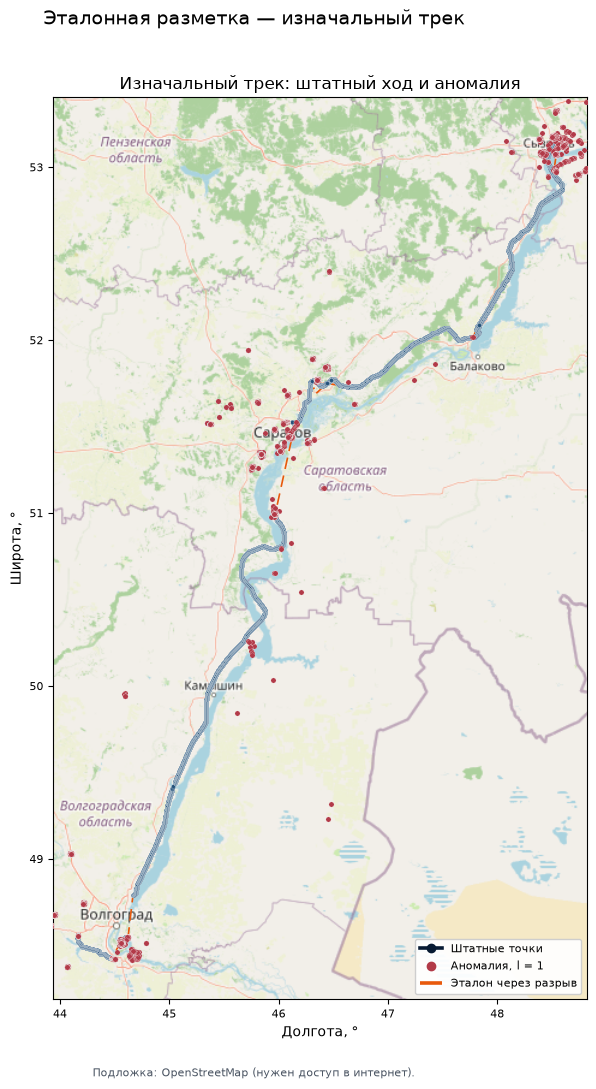

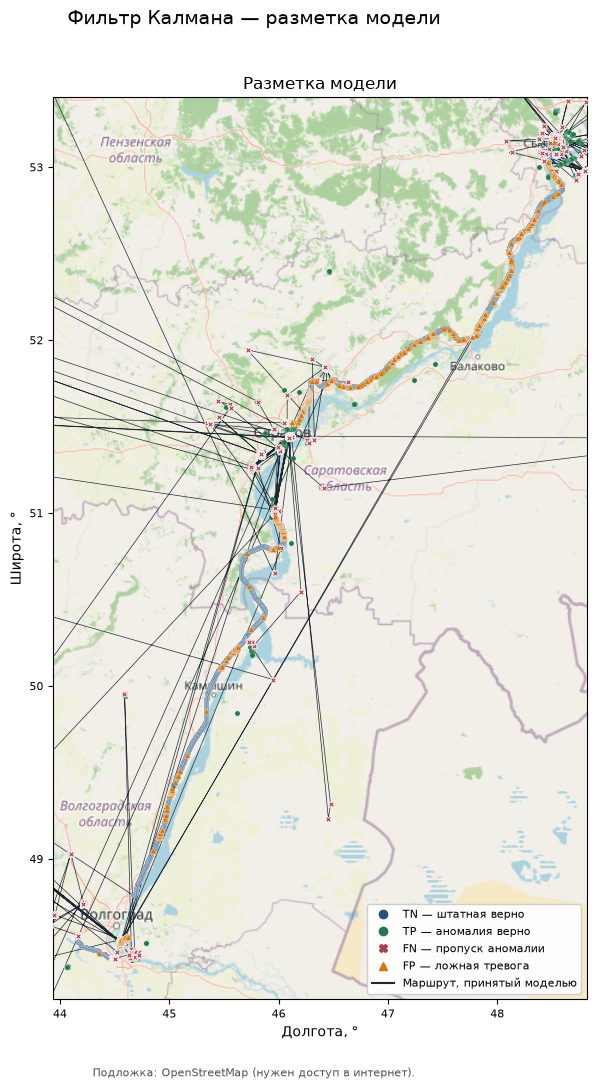

In [52]:
started = time.perf_counter()
sigma_acc, sigma_meas = fit_kalman_on_train(train)
speed_limit = restart_speed_limit(train)
selection = select_kalman_threshold(train, sigma_acc, sigma_meas, speed_limit, MCC_BAND)
print(f"σ_acc {sigma_acc:.4f} м/с², σ_meas {sigma_meas:.2f} м; предел скорости перезапуска {speed_limit:.2f} м/с")
print(
    f"χ²(2) = {KALMAN_CHI999:.2f}; порог {selection['tau']:.4g}: MCC {selection['train_mcc']:.4f} "
    f"(лучший {selection['best_mcc']:.4f}, в полосе {int(selection['band_size'])}), "
    f"DL_оп {selection['train_dl_m'] / 1000:.3f} км"
)

test_scores, test_rejected = kalman_detect(test, sigma_acc, sigma_meas, speed_limit, np.array([selection["tau"]]))
kalman_predicted = test_rejected[0]
kalman_scored = ~np.isnan(test_scores[0])
kalman_metrics = evaluate_test(test, kalman_predicted, kalman_scored)
print(f"Время расчёта: {time.perf_counter() - started:.1f} с")
display_test_report_table({"Фильтр Калмана": kalman_metrics}, caption="Метрики на тестовой выборке")

if SHOW_PLOTS:
    tail = min(PLOT_TAIL, len(test))
    prediction, ground_truth = trajectory_series_pair(test, kalman_predicted, kalman_scored)
    prediction = slice_trajectory_series(prediction, tail)
    ground_truth = slice_trajectory_series(ground_truth, tail)
    for panel, title in (("ground_truth", "Эталонная разметка"), ("model", "Фильтр Калмана")):
        plot_track_maps(prediction, ground_truth, map_panel=panel, title=title, figsize=MAP_FIGSIZE, annotate=False)